# Project 6: Weather Forecast Using Python APIs
**OOP with Python – Assignment 2 (2026)**  
**Programme:** MSc Data Science and Analytics

I developed a Python program to find a location and display its weather forecast. I used Open-Meteo and MET Norway, with tables, a chart and checks for errors. The assignment calls this Mini-Project 1, but I named my folder Project 6 to match my project numbering.

## 1. Setting Up the Project

I entered the city, forecast days and location choice here. I can also add my university email locally to use MET Norway.
I use `LIVE_REQUESTS = True` for live forecasts. I can set it to `False` when working offline.

In [60]:
CITY = "Kampala"
CANDIDATE_INDEX = 0
FORECAST_DAYS = 7
LIVE_REQUESTS = True  # I request current weather from the API.
UNIVERSITY_EMAIL = ""  # I add my email locally if I want to use MET Norway.
TIMEOUT_SECONDS = 20


## 2. Importing Libraries

I imported the libraries and functions from `src/weather.py`. I also checked the main project folder to avoid import errors.

In [61]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.weather import (Location, WeatherError, WeatherAPIError, InvalidLocationError, NoLocationsError, InvalidForecastError, geocode, geocode_requests, geocode_urllib, choose_location, get_forecast, parse_locations, parse_forecast, describe_weather, summary, plot_forecast, get_norway_forecast, parse_norway, request_json, validate_coordinates)
def load_sample(filename):
    with open(ROOT / "samples" / filename, encoding="utf-8") as f: return json.load(f)
print("Project folder:", ROOT)


Project folder: D:\MSDS\OOP\Assignment 2 mini project\Project_6_Weather_Forecast_Clean


## 3. Getting Location Details

I used both `urllib` and `requests` to search for a city. I checked the response status, content type and request time.
Live response details appear when I set `LIVE_REQUESTS = True`.

In [62]:
if LIVE_REQUESTS:
    for method in (geocode_urllib, geocode_requests):
        try:
            places, meta = method(CITY, timeout=TIMEOUT_SECONDS)
            print(method.__name__, "status:", meta["status_code"],
                  "type:", meta["content_type"],
                  "seconds:", meta["response_seconds"],
                  "candidates:", len(places))
        except WeatherError as exc:
            print(method.__name__, "unavailable:", str(exc)[:160])
else:
    print("Offline demonstration: I set LIVE_REQUESTS = True to check live HTTP responses.")


geocode_urllib status: 200 type: application/json; charset=utf-8 seconds: 0.833 candidates: 10
geocode_requests status: 200 type: application/json; charset=utf-8 seconds: 0.82 candidates: 10


## 4. Getting the Weather Forecast

I selected a location and requested its daily weather forecast. I displayed the results in a table and a graph. If the internet fails, I use clearly labelled sample data.

In [63]:
# I first try to find the city using the live geocoding API.
LIVE_GEOCODING = False
if LIVE_REQUESTS:
    try:
        candidates = geocode(CITY, timeout=TIMEOUT_SECONDS)
        if not candidates:
            raise NoLocationsError("No matching locations")
        LIVE_GEOCODING = True
    except WeatherError as exc:
        print("Live location search failed:", exc)

if not LIVE_GEOCODING:
    if CITY.strip().casefold() == "kampala":
        candidates = [Location("Kampala", 0.3476, 32.5825, "Uganda", "Central Region", "Africa/Kampala")]
        print("Using saved Kampala coordinates. I will still request a LIVE forecast.")
    else:
        candidates = parse_locations(load_sample("geocoding_sample.json"))
        print("Using INVENTED SAMPLE locations. Check the selected coordinates before relying on them.")

for i, place in enumerate(candidates):
    print(f"[{i}] {place.label} ({place.latitude}, {place.longitude}), {place.timezone}")
location = choose_location(candidates, CANDIDATE_INDEX)
print("Selected:", location.label)


[0] Kampala, Central Region, Uganda (0.31628, 32.58219), Africa/Kampala
[1] Kampala, Montagnes, Ivory Coast (7.32344, -7.68519), Africa/Abidjan
[2] Kampala, Ituri, Democratic Republic of Congo (2.30086, 30.59269), Africa/Lubumbashi
[3] Kampala, South Kivu, Democratic Republic of Congo (-2.19509, 27.74864), Africa/Lubumbashi
[4] Kampala, Eastern Province, Zambia (-14.41129, 31.6098), Africa/Lusaka
[5] Kampala, South Sulawesi, Indonesia (-5.0135, 119.5249), Asia/Makassar
[6] Kampala, South Sulawesi, Indonesia (-5.0031, 119.7811), Asia/Makassar
[7] Kampala, South Sulawesi, Indonesia (-5.1504, 120.0588), Asia/Makassar
[8] Kampala, South Sulawesi, Indonesia (-5.1541, 120.223), Asia/Makassar
[9] Kampala, South Sulawesi, Indonesia (-5.4758, 120.0053), Asia/Makassar
Selected: Kampala, Central Region, Uganda


In [64]:

# I first try to get live weather data from Open-Meteo.
LIVE_FORECAST = False

if LIVE_REQUESTS:
    try:
        payload, forecast_meta = get_forecast(
            location.latitude,
            location.longitude,
            FORECAST_DAYS,
            timezone_name=location.timezone,
            timeout=TIMEOUT_SECONDS
        )

        LIVE_FORECAST = True
        print("Live API status:", forecast_meta["status_code"])

    except WeatherError as exc:
        print("Live forecast request failed:", exc)

# If the live request fails, I use saved sample data.
if not LIVE_FORECAST:
    payload = load_sample("open_meteo_sample.json")
    print("INVENTED SAMPLE - NOT CURRENT WEATHER")
else:
    print("LIVE Open-Meteo forecast")

# I convert the weather data into a table.
forecast_table = parse_forecast(payload)
display(forecast_table)

# I display the summary using the existing function.
print(summary(forecast_table, location))

# I clearly identify whether the weather data is live or sample.
if LIVE_FORECAST:
    print("Data source: Live Open-Meteo API")
else:
    print("Data source: Invented sample data - not current weather")


Live API status: 200
LIVE Open-Meteo forecast


,Date,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind (km/h),Weather
0,2026-10-21,28.0,18.8,0.0,10.1,Overcast
1,2026-10-22,27.1,19.9,1.7,13.5,Dense drizzle
2,2026-10-23,26.9,19.0,11.6,12.0,Violent rain showers
3,2026-10-24,25.9,19.0,3.9,13.3,Moderate drizzle
4,2026-10-25,26.1,18.8,4.5,10.5,Moderate drizzle
5,2026-10-26,25.7,18.7,3.6,11.0,Moderate drizzle
6,2026-10-27,27.1,19.1,1.8,7.7,Light drizzle


Kampala, Central Region, Uganda: 7-day forecast. Maximum temperatures 25.7–28.0 °C; total precipitation 27.1 mm. Source: Open-Meteo (open-meteo.com).
Data source: Live Open-Meteo API


In [65]:
# I display the weather summary and identify the data source.
print(summary(forecast_table, location))

if LIVE_FORECAST:
    print("Data source: LIVE Open-Meteo forecast")
else:
    print("Data source: INVENTED SAMPLE - NOT CURRENT WEATHER")

Kampala, Central Region, Uganda: 7-day forecast. Maximum temperatures 25.7–28.0 °C; total precipitation 27.1 mm. Source: Open-Meteo (open-meteo.com).
Data source: LIVE Open-Meteo forecast


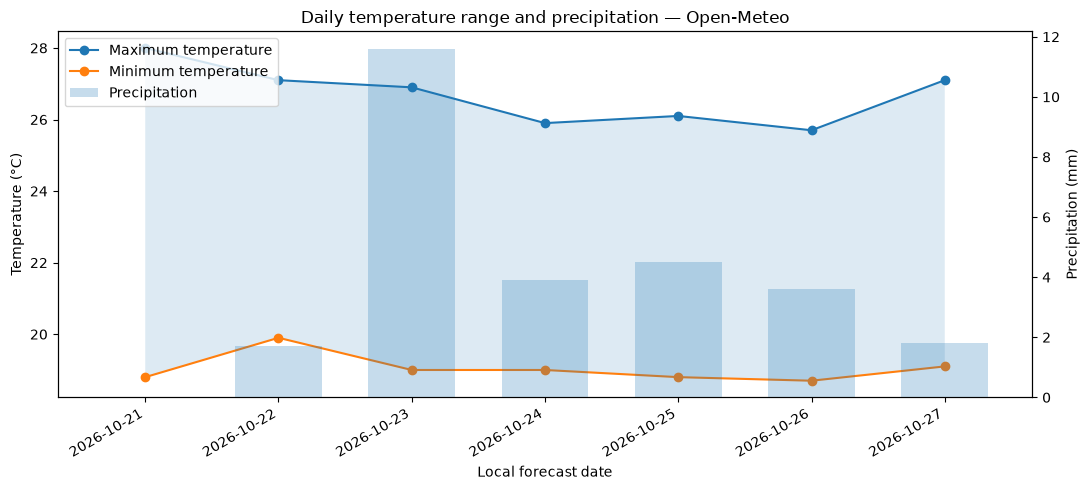

In [66]:
figure = plot_forecast(forecast_table)
plt.show()


## 5. Checking MET Norway

I used MET Norway as a second weather source. Its data is hourly, so I do not compare it directly with Open-Meteo's daily values. A live request needs my own university email.

In [67]:
# I use MET Norway only when I provide my own contact email.
LIVE_NORWAY = False
if LIVE_REQUESTS and UNIVERSITY_EMAIL.strip() and "@" in UNIVERSITY_EMAIL and not UNIVERSITY_EMAIL.endswith("@example.com"):
    try:
        norway_data, norway_meta = get_norway_forecast(
            location.latitude, location.longitude,
            contact_email=UNIVERSITY_EMAIL, timeout=TIMEOUT_SECONDS
        )
        LIVE_NORWAY = True
    except WeatherError as exc:
        print("MET Norway request failed:", exc)
if not LIVE_NORWAY:
    norway_data = load_sample("met_norway_sample.json")
    print("INVENTED MET Norway SAMPLE — add UNIVERSITY_EMAIL for a live request.")
norway_table = parse_norway(norway_data)
display(norway_table.head(8))
print("Source:", "Live MET Norway (api.met.no)" if LIVE_NORWAY else "Invented sample JSON")


INVENTED MET Norway SAMPLE — add UNIVERSITY_EMAIL for a live request.


,Time (UTC),Temperature (°C),Wind speed (m/s),Next-hour precipitation (mm)
0,2026-10-17T09:00:00Z,25.0,3.1,0.5


Source: Invented sample JSON


## 6. Handling Errors

I tested invalid locations, incorrect coordinates and network failures to see whether the program gives clear error messages.

In [68]:
import requests
class OfflineSession:
    def get(self,*args,**kwargs): raise requests.ConnectionError("Simulated offline network")
for label, action in [
    ("Invalid city", lambda: geocode(" ")),
    ("Invalid latitude", lambda: validate_coordinates(1000,32)),
    ("No matches", lambda: choose_location(parse_locations({"results":[]}))),
    ("Simulated no network", lambda: request_json("https://example.invalid",session=OfflineSession(),retries=1,backoff=0)),
]:
    try: action()
    except (WeatherError,ValueError) as exc: print(label,"->",type(exc).__name__,str(exc)[:120])
if LIVE_GEOCODING:
    try: geocode_requests(CITY,timeout=0.000001)
    except WeatherError as exc: print("Tiny timeout ->",type(exc).__name__,str(exc)[:120])
else: print("Tiny timeout live test skipped because network is unavailable")


Invalid city -> InvalidLocationError Enter at least two letters
Invalid latitude -> InvalidLocationError Latitude must be -90 to 90; longitude -180 to 180.
No matches -> NoLocationsError No matching locations
Simulated no network -> WeatherAPIError Failed after 2 attempt(s): Simulated offline network
Tiny timeout -> WeatherAPIError Failed after 3 attempt(s): HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with


## 7. Testing the Results

I used saved sample data to test the location search, weather codes, forecasts and error handling without the internet.

In [69]:
geo = load_sample("geocoding_sample.json")
weather = load_sample("open_meteo_sample.json")
assert len(parse_locations(geo)) == 2
assert parse_locations({}) == []
assert choose_location(parse_locations(geo),1).country == "Sampleland"
assert describe_weather(61) == "Slight rain"
assert describe_weather(999).startswith("Unknown")
assert len(parse_forecast(weather)) == 3
assert parse_forecast(weather)["Precipitation (mm)"].sum() == 10.6
assert len(parse_norway(load_sample("met_norway_sample.json"))) == 1
try: parse_forecast({"daily":{"time":["2026-10-17"]}})
except InvalidForecastError: pass
else: raise AssertionError("Expected malformed forecast to fail")
print("All nine offline assertions passed.")


All nine offline assertions passed.


## 8. What I Learnt and the Project's Limitations

I explain how the program works, how I handled failed requests and what I considered when using public weather APIs.

### Data Flow and Program Design

I started with a city name because it is easier to enter than coordinates. The program sends the name to Open-Meteo and gets possible matching locations. Some places have the same name, so I display the choices and use the selected location. Each location has a name, country, coordinates and timezone.

My program follows this process:

**City name --->  matching locations ---> selected coordinates to weather API  JSON data ---> table and graph**

I requested daily maximum and minimum temperatures, rainfall, wind speed and weather codes. I used the location's timezone so the dates match the local forecast. The weather codes are changed into simple descriptions such as clear sky or rain.

I kept the reusable code in `src/weather.py` instead of writing everything in the notebook. I used a `Location` class to group the details of each place. I also wrote separate functions for requests, checking values and preparing the results. This made the code easier to read and test.

Before displaying a forecast, I check that the required values are present and that the daily data has matching lengths. This helps prevent incorrect tables.

### Comparing urllib and requests

I used `urllib` and `requests` to make the same location search. Both can send HTTP requests and receive JSON data. With `urllib`, I had to build the query string, open the URL and decode the response. It works without installing an extra HTTP library, but it needs more code.

I found `requests` easier to use because it accepts query values through `params` and provides simple methods for checking HTTP errors and reading JSON. It also lets me set a timeout clearly.

I checked the status code, Content-Type and response time for each successful live request. A status code of 200 shows that the request succeeded, but I still need to check the returned data. The response time may change depending on the network and server.

I used `requests` for the main forecast functions because it made retries and error handling easier. I kept the `urllib` example to show that I understand both methods.

### Errors, Retries and Offline Data

Weather APIs may fail when the internet is slow, the server is unavailable or a request takes too long. I added a timeout so the program does not wait forever. I also added retries for temporary connection problems and selected server errors. The waiting time increases after each failed attempt, but the number of retries is limited.

I used custom errors to explain problems instead of letting the program fail without a clear message. For example, the program rejects a latitude outside -90 to 90, an invalid longitude and an unsupported number of forecast days. It also checks that the weather data contains the expected fields.

I tested an empty city name, incorrect coordinates and a simulated network failure. These tests helped me check whether the program handles problems properly.

When live data is unavailable, I use saved sample JSON to demonstrate the table and graph. I clearly label it as sample data because it is not the current weather forecast. The offline tests also use this saved data, which means I can check the main calculations without internet access.

The sample files are only for learning and testing. They should not be used to make real weather decisions.

### Using MET Norway as a Second Source

I included MET Norway to see how weather information from another provider can be handled. Open-Meteo gives daily values, while MET Norway provides weather measurements and forecasts for specific times. I extracted temperature, wind speed and precipitation from its response.

I found that the two sources cannot be compared directly without checking the times and units. For example, a daily maximum temperature is different from a temperature recorded at one hour. A fair comparison would need matching dates, times and measurements.

MET Norway also asks users to identify their application through a User-Agent. I therefore left a place to enter my real university email in the notebook. I did not put personal contact details in the shared source code.

If I do not provide an email, or if the network fails, the notebook uses a saved sample response. The sample is labelled so it cannot be confused with live MET Norway data. This also helps the notebook run from beginning to end.

### API Terms and Data Sources

I used Open-Meteo and MET Norway because they provide weather information through public APIs. However, public access does not mean that every type of use is allowed without conditions.

Open-Meteo has documentation and terms covering how its data and services may be used. Its non-commercial and commercial arrangements may differ. If I wanted to turn this project into a business application, I would first check the current terms, usage limits and any required licence.

MET Norway also has terms for using its API and weather data. These include identifying the application, respecting service usage rules and giving proper credit to the source. A larger system would need to avoid unnecessary requests and consider caching data.

I have included links to both providers in the README and notebook references. I identify the data source when displaying the results.

The saved JSON files in my project are invented examples for testing. They are not actual observations from the weather providers. I would need live, properly attributed data for any real weather report.

### Privacy, Findings and Limitations

I learnt that searching for a city through an API sends the location name to another service. The provider may also receive information such as the request time and IP address. For this project, I used a general city name rather than a private home address. I also avoided saving my email in the shared code.

The project showed me how to connect Python to web APIs, read JSON and present weather data clearly. The table makes it easy to see the daily values, while the graph shows temperature changes and rainfall. I also learnt why checking the data matters before using it.

The main limitation is that the program depends on external services and internet access. A request may fail or a provider may change its response format. The retry system helps with temporary problems but cannot guarantee that live data will always be available.

Another limitation is that the MET Norway and Open-Meteo results use different time periods. I would need extra processing to compare their forecasts fairly.

Overall, I developed a working example that can use live weather data or clearly labelled offline samples. It is suitable for learning, but a public weather service would need more checks, monitoring and attention to provider terms.

## References and AI Assistance

- [Open-Meteo forecast documentation](https://open-meteo.com/en/docs)
- [Open-Meteo geocoding documentation](https://open-meteo.com/en/docs/geocoding-api)
- [Open-Meteo terms](https://open-meteo.com/en/terms)
- [MET Norway documentation](https://api.met.no/weatherapi/locationforecast/2.0/documentation)
- [MET Norway terms](https://api.met.no/doc/TermsOfService)
- [MET Norway licence](https://api.met.no/doc/License)

I used AI assistance to help organise the code, tests and explanations. I have kept the project open for testing and review.

**Note:** The notebook opens in offline demonstration mode. I set `LIVE_REQUESTS = True` to use the live APIs.